In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
import joblib
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression

#### Loading Data

In [2]:
df = pd.read_csv('data/fitness_data.csv')

In [4]:
df.head(5)

,is_premium,age,weekly_mins,avg_hr,workout_type,region
0,0,27,34,122.160313,HIIT,South
1,1,32,217,122.709436,Running,South
2,0,38,172,127.317362,Yoga,North
3,0,19,317,NaN,Yoga,East
4,1,18,37,131.646910,Yoga,West


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 6 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   is_premium    2000 non-null   int64  
 1   age           2000 non-null   int64  
 2   weekly_mins   2000 non-null   int64  
 3   avg_hr        1800 non-null   float64
 4   workout_type  2000 non-null   object 
 5   region        2000 non-null   object 
dtypes: float64(1), int64(3), object(2)
memory usage: 93.9+ KB


In [6]:
df.shape

(2000, 6)

In [10]:
df.duplicated().sum()

np.int64(0)

In [11]:
df.isnull().sum()

is_premium        0
age               0
weekly_mins       0
avg_hr          200
workout_type      0
region            0
dtype: int64

#### 1. You are deploying a model to a mobile app. Why is it dangerous to use manual `fillna()` and `get_dummies()` before splitting your data?

In [3]:
# it allpws the model to cheat by seeing patterns in the test data, leading to fake high accuracy.

#### Split the data

In [14]:
X = df.drop('is_premium', axis=1)

# Target (y): The binary column we are trying to predict.
y = df['is_premium']


X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42)
print("Data Split Complete.")

Data Split Complete.


#### Visualizing User Activity Gaps

In [15]:
# run the code below

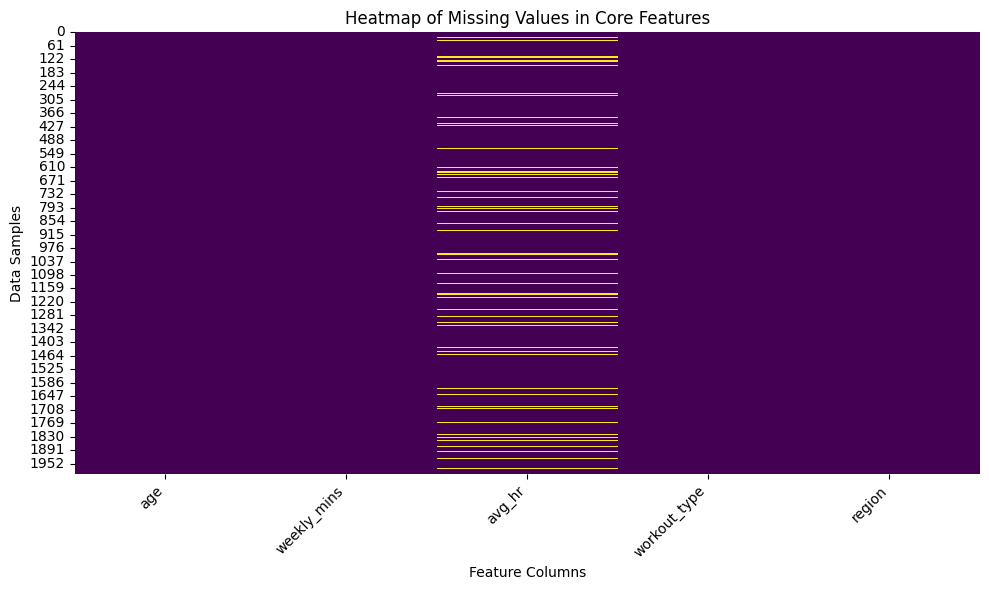

In [16]:
core_features = ['age', 'weekly_mins', 'avg_hr', 'workout_type', 'region']

df_core_viz = df[core_features] 

plt.figure(figsize=(10, 6))

sns.heatmap(df_core_viz.isna(), cbar=False, cmap='viridis')

plt.title('Heatmap of Missing Values in Core Features')
plt.xlabel('Feature Columns')
plt.ylabel('Data Samples')
plt.xticks(rotation=45, ha='right')

plt.tight_layout()
plt.show()

#### 2. Build the Numeric Cleaning Pipeline

In [19]:
# Numeric pipeline
numeric_pipeline = Pipeline([
    ('impute', SimpleImputer(strategy = "median")),  # fill NaNs
    ('scale', StandardScaler())
])

#### 3. Build the Categorical Encoding Pipeline

In [21]:
# Categorical pipeline
categorical_pipeline = Pipeline([
    ('onehot', OneHotEncoder(drop = 'first', sparse_output = False))
])

#### 4. Combine Pipelines Using ColumnTransformer

In [28]:
# ColumnTransformer
numerical_col = ['age', 'weekly_mins', 'avg_hr']
categorical_col = ['workout_type', 'region']
engine = ColumnTransformer(transformers=[
    ('numeric', numeric_pipeline, numerical_col),
    ('categorical', categorical_pipeline, categorical_col)
])

#### 5. What does StandardScaler actually do to our user activity metrics?

In [30]:
#it centers the data around zero so that different units (like minute vs. age) are been compare.

#### 6. Chaining it All Together

In [32]:
# The Complete Conversion Pipeline
app_model = Pipeline(steps=[
    ('cleaning_engine', engine),
    ('classifier', LogisticRegression())
])

# Train the entire system
app_model.fit(X_train, y_train)

Pipeline(steps=[('cleaning_engine',
                 ColumnTransformer(transformers=[('numeric',
                                                  Pipeline(steps=[('impute',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scale',
                                                                   StandardScaler())]),
                                                  ['age', 'weekly_mins',
                                                   'avg_hr']),
                                                 ('categorical',
                                                  Pipeline(steps=[('onehot',
                                                                   OneHotEncoder(drop='first',
                                                                                 sparse_output=False))]),
                                                  ['workout_type',
                                                   'region'])])),
                ('classifier', LogisticRegression())])

#### 7. What happens internally when `app_model.predict(new_user)` is called and `avg_hr` is missing?

In [34]:
# the pipeline fills the missing value using the learned median, encodes, "hiit", scales the input and then makes a prediction

#### 8. Predicting the Next "Premium" User

In [42]:
new_user = pd.DataFrame({
    'age': [25],
    'weekly_mins': [150],
    'avg_hr': [np.nan], # Missing data!
    'workout_type': ['HIIT'],
    'region': ['North']
})

# One command handles everything
is_premium = app_model.predict(new_user)

print("Will they upgrade?", "Yes" if is_premium[0] == 1 else "No")

Will they upgrade? No


#### 9. Why is this .predict() call better than the manual way?

In [ ]:
# it automatically applies the